In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer


In [3]:
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame.copy()

In [4]:
display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (569, 31)

Column Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           5

In [6]:
print("Target Names:", cancer.target_names)

print("\nClass Distribution:")
print(df["target"].value_counts())

print("\nClass Distribution with Names:")
print(
    df["target"].map(
        {0: "Malignant", 1: "Benign"}
    ).value_counts()
)


Target Names: ['malignant' 'benign']

Class Distribution:
target
1    357
0    212
Name: count, dtype: int64

Class Distribution with Names:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [7]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [8]:
missing_values = df.isnull().sum()

print(missing_values)

print(missing_values.sum())


mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64
0


In [11]:
duplicates = df.duplicated().sum()
print("number of duplicate rows:", duplicates)

number of duplicate rows: 0


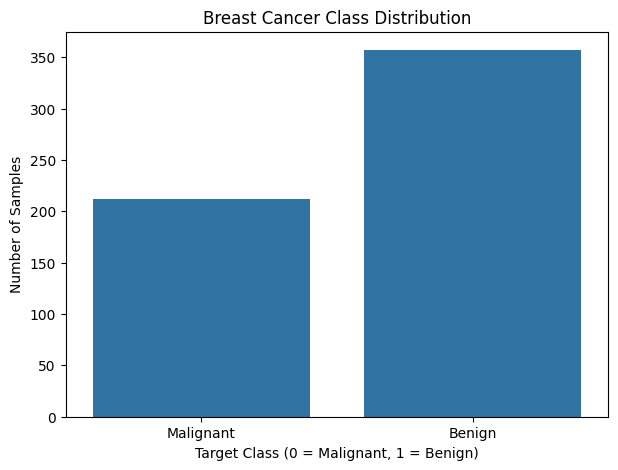

In [12]:
class_counts = df["target"].value_counts().sort_index()
plt.figure(figsize=(7, 5))

sns.countplot(data=df,x="target")
plt.title("Breast Cancer Class Distribution")
plt.xlabel("Target Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])
plt.show()

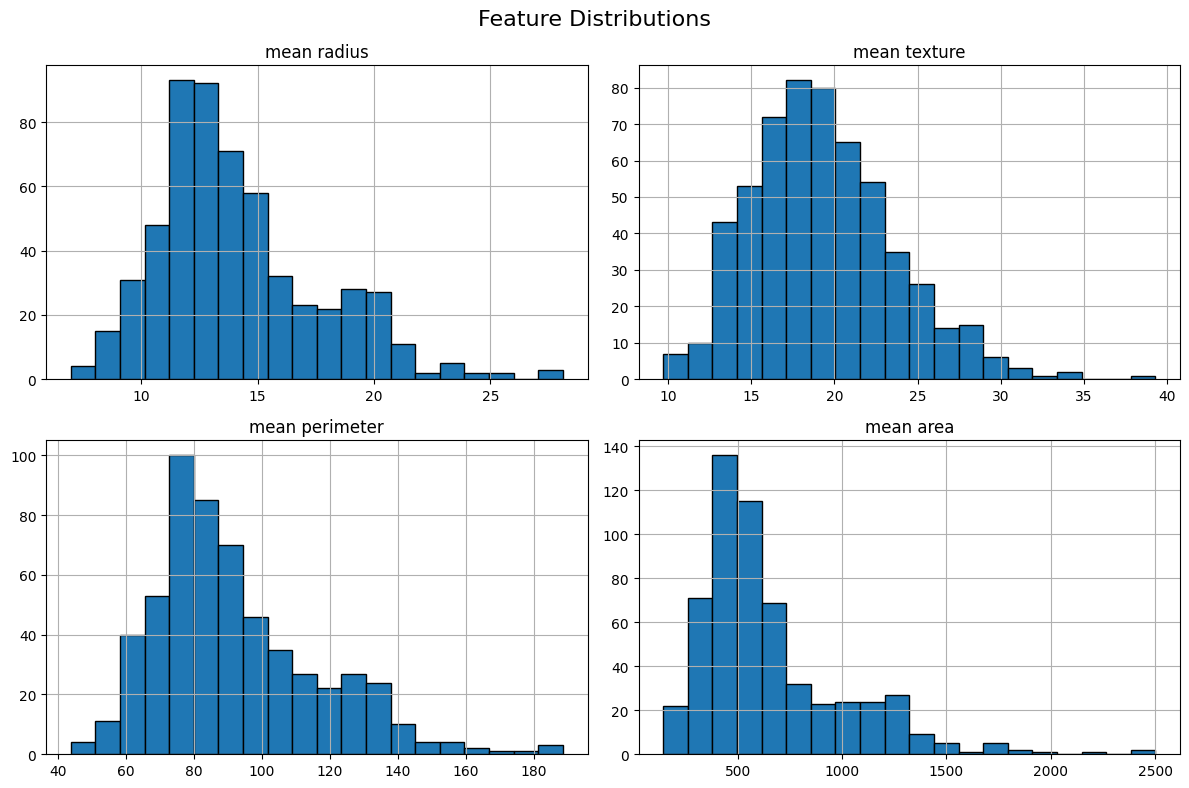

In [13]:
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]
df[selected_features].hist(figsize=(12, 8),bins=20,edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()


In [14]:
X = df.drop(columns=["target"])
y = df["target"]
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())


Features Shape: (569, 30)
Target Shape: (569,)

Features:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("training Features:", X_train.shape)
print("testing Features:", X_test.shape)
print("training Target:", y_train.shape)
print("testing Target:", y_test.shape)


training Features: (455, 30)
testing Features: (114, 30)
training Target: (455,)
testing Target: (114,)


In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("scaled training shape:", X_train_scaled.shape)
print("scaled testing shape:", X_test_scaled.shape)
print("\ntraining mean (first 5 features):")
print(X_train_scaled.mean(axis=0)[:5])
print("\ntraining standard deviation (first 5 features):")
print(X_train_scaled.std(axis=0)[:5])

scaled training shape: (455, 30)
scaled testing shape: (114, 30)

training mean (first 5 features):
[-2.92806072e-16  6.24652955e-16 -1.62995380e-16 -1.71779562e-16
  6.24652955e-17]

training standard deviation (first 5 features):
[1. 1. 1. 1. 1.]


In [19]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000,random_state=42)

In [20]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [21]:
print("Model Weights:")
print(model.coef_)

print("\nModel Bias:")
print(model.intercept_)

print("\nNumber of Features:", len(model.coef_[0]))


Model Weights:
[[-0.51147901 -0.55269775 -0.47629789 -0.54105924 -0.21247927  0.64834159
  -0.60210291 -0.70415649 -0.16723273  0.19973173 -1.08296534  0.24882301
  -0.54433323 -0.92910402 -0.16027571  0.64722656  0.16056252 -0.44378424
   0.36049156  0.43789426 -0.94761615 -1.25508804 -0.76322007 -0.9477559
  -0.74662481  0.05551412 -0.82315065 -0.95368636 -0.93918141 -0.1872508 ]]

Model Bias:
[0.30220757]

Number of Features: 30


In [22]:
y_pred = model.predict(X_test_scaled)
print("First 10 Predictions:")
print(y_pred[:10])
print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)


First 10 Predictions:
[0 1 0 1 0 1 1 0 0 0]

First 10 Actual Values:
[0 1 0 1 0 1 1 0 0 0]


In [24]:
y_prob = model.predict_proba(X_test_scaled)
print("first 10 Probabilities:")
print(y_prob[:10])

print("\nmodel classes:")
print(model.classes_)


first 10 Probabilities:
[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]
 [7.83960163e-03 9.92160398e-01]
 [1.71746799e-05 9.99982825e-01]
 [9.99999436e-01 5.63527494e-07]
 [9.99945684e-01 5.43163692e-05]
 [1.00000000e+00 8.04184941e-11]]

model classes:
[0 1]


In [25]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
test_values = np.array([-5, -2, 0, 2, 5])

print("Input Values:")
print(test_values)

print("\nSigmoid Outputs:")
print(sigmoid(test_values))


Input Values:
[-5 -2  0  2  5]

Sigmoid Outputs:
[0.00669285 0.11920292 0.5        0.88079708 0.99330715]


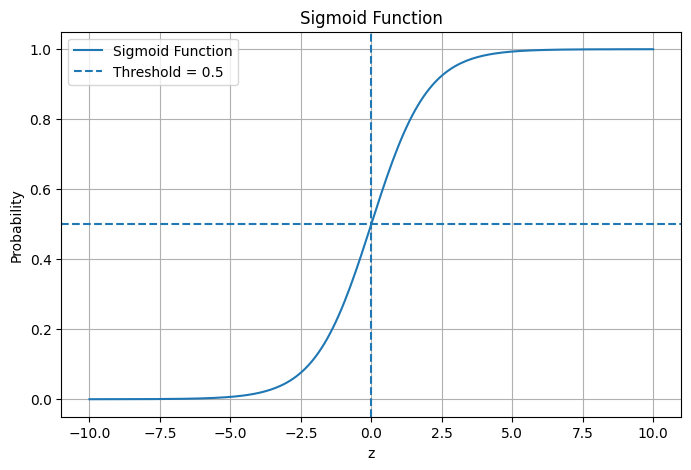

In [26]:
z_values = np.linspace(-10, 10, 200)
probabilities = sigmoid(z_values)
plt.figure(figsize=(8, 5))
plt.plot(z_values, probabilities, label="Sigmoid Function")
plt.axhline(0.5, linestyle="--", label="Threshold = 0.5")
plt.axvline(0, linestyle="--")
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
def softmax(z):
    exp_values = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return exp_values / np.sum(exp_values,axis=-1,keepdims=True)
test_scores = np.array([2.0, 1.0, 0.1])
softmax_output = softmax(test_scores)
print("Softmax Probabilities:")
print(softmax_output)
print("\nSum of Probabilities:")
print(np.sum(softmax_output))

Softmax Probabilities:
[0.65900114 0.24243297 0.09856589]

Sum of Probabilities:
1.0


In [28]:
def cross_entropy_loss(y_true, y_prob):

    epsilon = 1e-15
    y_prob = np.clip(y_prob,epsilon,1 - epsilon)
    loss = -( y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob) )
    return np.mean(loss)

actual_values = np.array([1, 0, 1, 0])

predicted_probabilities = np.array([ 0.9, 0.2, 0.8, 0.1])

loss = cross_entropy_loss(actual_values,predicted_probabilities)
print("Cross-Entropy Loss:", loss)

Cross-Entropy Loss: 0.16425203348601802


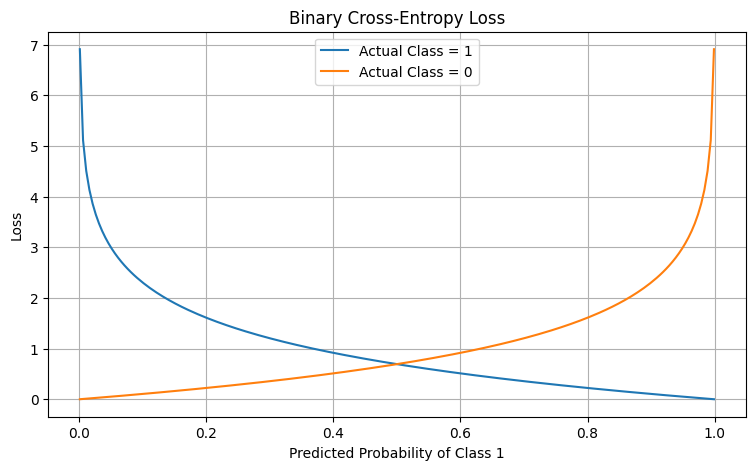

In [29]:
p = np.linspace(0.001, 0.999, 200)
loss_class_1 = -np.log(p)
loss_class_0 = -np.log(1 - p)
plt.figure(figsize=(9, 5))
plt.plot(p, loss_class_1, label="Actual Class = 1")
plt.plot(p, loss_class_0, label="Actual Class = 0")
plt.title("Binary Cross-Entropy Loss")
plt.xlabel("Predicted Probability of Class 1")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
from sklearn.linear_model import LogisticRegression
X_2d = df[["mean radius", "mean texture"]]
y_2d = df["target"]
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
model_2d = LogisticRegression(max_iter=1000, random_state=42)
model_2d.fit(X_train_2d_scaled, y_train_2d)

LogisticRegression(max_iter=1000, random_state=42)

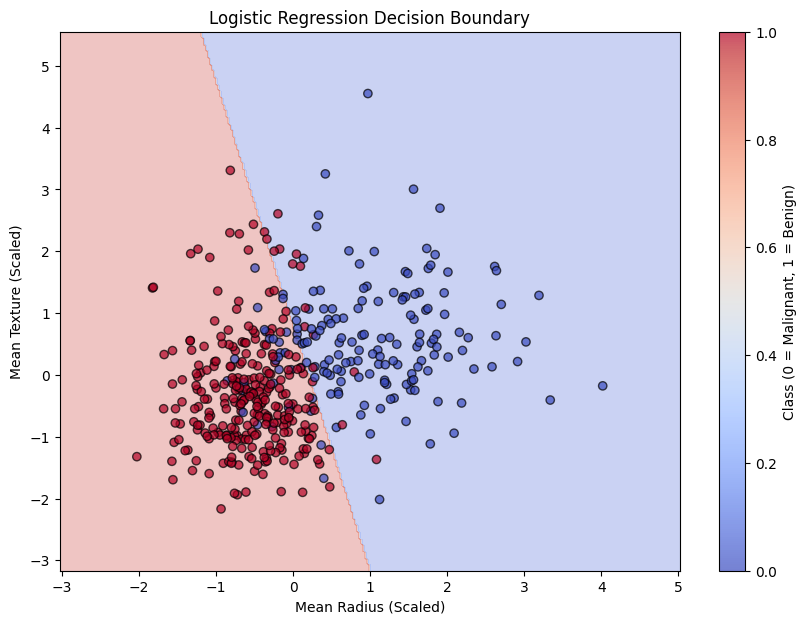

In [31]:
x_min, x_max = X_train_2d_scaled[:, 0].min() - 1, X_train_2d_scaled[:, 0].max() + 1
y_min, y_max = X_train_2d_scaled[:, 1].min() - 1, X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = model_2d.predict(grid_points)
Z = Z.reshape(xx.shape)
plt.figure(figsize=(10, 7))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=y_train_2d,
    cmap="coolwarm",
    edgecolors="black",
    alpha=0.7
)
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Mean Radius (Scaled)")
plt.ylabel("Mean Texture (Scaled)")
plt.colorbar(label="Class (0 = Malignant, 1 = Benign)")
plt.show()

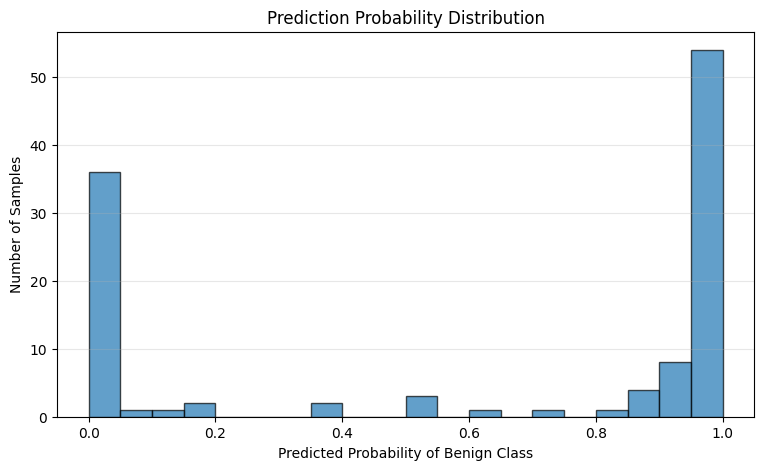

In [32]:
y_prob = model.predict_proba(X_test_scaled)
benign_probabilities = y_prob[:, 1]
plt.figure(figsize=(9, 5))
plt.hist(benign_probabilities,bins=20,edgecolor="black",alpha=0.7)
plt.title("Prediction Probability Distribution")
plt.xlabel("Predicted Probability of Benign Class")
plt.ylabel("Number of Samples")
plt.grid(axis="y", alpha=0.3)
plt.show()